# Gridworld control: policy iteration and value iteration

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/reinforcement-learning/03-gridworld-control.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In the previous notebook, we evaluated a fixed policy. Now we use the same Gridworld and its known environment model to find a policy that maximizes expected discounted return.

## What we will do

1. Set up the same Gridworld model.
2. Compute action values from the value function of a policy.
3. Alternate policy evaluation and greedy improvement with **policy iteration**.
4. Use **value iteration** to fold those two ideas into one Bellman-optimality update.

The policy-evaluation code is included here so you can run this notebook on its own.

In [1]:
from collections.abc import Iterator

import matplotlib.axes as mpl_axes
import matplotlib.colors as mpl_colors
import matplotlib.image as mpl_image
import matplotlib.pyplot as plt
import numpy as np
from numpy import typing as npt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

State = tuple[int, int]  # (row, column)
FloatArray = npt.NDArray[np.float64]

## 1. Set up the Gridworld model

Both algorithms use the known transition model. Given state $s$ and action $a$, the function `transition()` returns the next state $s'$ and immediate reward $r$.

In [2]:
GRID_SIZE = 5
GAMMA = 0.9

# The action order matches the policy-evaluation notebook and the explorers.
ACTIONS = [
    ("up", -1, 0, "↑"),
    ("right", 0, 1, "→"),
    ("down", 1, 0, "↓"),
    ("left", 0, -1, "←"),
]
N_ACTIONS = len(ACTIONS)

A = (0, 1)
A_PRIME = (4, 1)
B = (0, 3)
B_PRIME = (2, 3)

TELEPORTS = {
    A: (A_PRIME, 10.0),
    B: (B_PRIME, 5.0),
}
SPECIAL_LABELS = {A: "A", A_PRIME: "A′", B: "B", B_PRIME: "B′"}


def states() -> Iterator[State]:
    """Yield all 25 (row, column) pairs, with indices starting at 0."""
    for row in range(GRID_SIZE):
        for column in range(GRID_SIZE):
            yield (row, column)


def in_grid(state: State) -> bool:
    """Return whether the state lies inside the board."""
    row, column = state
    return 0 <= row < GRID_SIZE and 0 <= column < GRID_SIZE


def transition(state: State, action_index: int) -> tuple[State, float]:
    """Apply one action in the deterministic Gridworld.

    Args:
        state: Current (row, column) position.
        action_index: Index of the chosen action in ACTIONS.

    Returns:
        The next state and immediate reward.
    """
    if state in TELEPORTS:
        return TELEPORTS[state]

    _, row_change, column_change, _ = ACTIONS[action_index]
    row, column = state
    candidate = (row + row_change, column + column_change)
    if not in_grid(candidate):
        return state, -1.0
    return candidate, 0.0


for source, (destination, reward) in TELEPORTS.items():
    print(
        f"{SPECIAL_LABELS[source]} at {source} → "
        f"{SPECIAL_LABELS[destination]} at {destination}, "
        f"reward {reward:+.0f}"
    )

A at (0, 1) → A′ at (4, 1), reward +10
B at (0, 3) → B′ at (2, 3), reward +5


## 2. From state values to action values

For a fixed policy $\pi$, the state value $v_\pi(s)$ averages over actions. The **action value** keeps the first action explicit:

$$
q_\pi(s,a) = r(s,a,s') + \gamma v_\pi(s').
$$

The Gridworld is deterministic, so each $(s,a)$ has exactly one $s'$ and one immediate reward. The code computes all four action values at a state, then policy evaluation averages them according to the current policy.

In [3]:
def uniform_random_policy() -> FloatArray:
    """Return π(a|s)=1/4 for every state and action."""
    return np.full((GRID_SIZE, GRID_SIZE, N_ACTIONS), 1.0 / N_ACTIONS)


def action_values(values: FloatArray, state: State) -> FloatArray:
    """Compute the one-step returns r + γV(s′) at a state.

    Args:
        values: Current state values, indexed by row and column.
        state: State from which to consider each action.

    Returns:
        One return per action, in ACTIONS order.
    """
    q_values = np.empty(N_ACTIONS)
    for action_index in range(N_ACTIONS):
        next_state, reward = transition(state, action_index)
        q_values[action_index] = reward + GAMMA * values[next_state]
    return q_values


def evaluate_policy(
    policy: FloatArray,
    tolerance: float = 1e-4,
    max_sweeps: int = 10_000,
) -> tuple[FloatArray, FloatArray]:
    """Evaluate a fixed policy by synchronous Bellman expectation backups.

    Args:
        policy: Action probabilities indexed by row, column, and action.
        tolerance: Stop when the maximum value change falls below this.
        max_sweeps: Maximum number of Bellman sweeps.

    Returns:
        The final value grid and the maximum change from each sweep.

    Raises:
        RuntimeError: If the values do not converge within max_sweeps.
    """
    values = np.zeros((GRID_SIZE, GRID_SIZE))
    changes = []

    for _ in range(max_sweeps):
        # Every backup uses the previous value grid, not the new one.
        next_values = np.zeros_like(values)
        for state in states():
            next_values[state] = policy[state] @ action_values(values, state)

        max_change = np.max(np.abs(next_values - values))
        changes.append(max_change)
        values = next_values
        if max_change < tolerance:
            break
    else:
        raise RuntimeError("Policy evaluation did not converge.")

    return values, np.asarray(changes)


random_policy = uniform_random_policy()
random_values, random_changes = evaluate_policy(random_policy)

example_state = (2, 2)
action_names = [action[0] for action in ACTIONS]
print(f"Random-policy evaluation converged in {len(random_changes)} sweeps.")
print(f"Action values at {example_state}:")
print(
    pd.Series(
        action_values(random_values, example_state), index=action_names
    ).round(3)
)

Random-policy evaluation converged in 47 sweeps.
Action values at (2, 2):
up       2.026
right    0.323
down    -0.319
left     0.665
dtype: float64


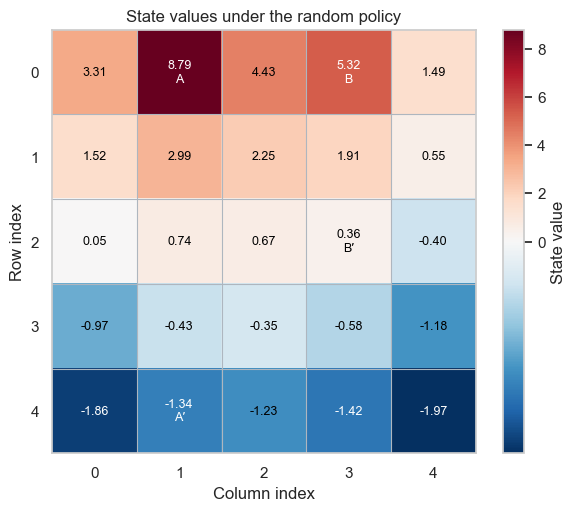

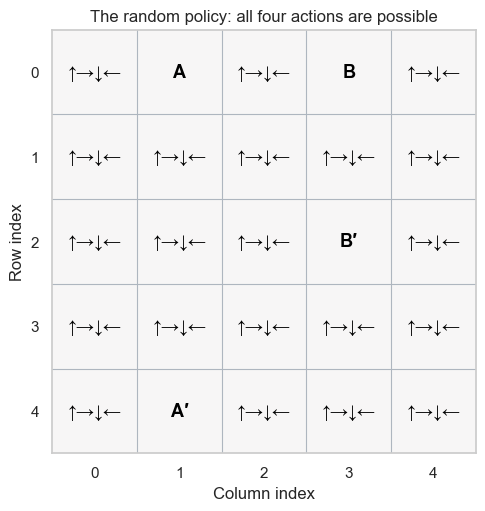

In [4]:
def draw_value_grid(
    values: FloatArray, title: str, ax: mpl_axes.Axes
) -> mpl_image.AxesImage:
    """Draw the 5-by-5 heatmap and place gridlines between cells.

    Args:
        values: Matrix indexed by row and column.
        title: Title displayed above the grid.
        ax: Matplotlib axes on which to draw the grid.

    Returns:
        The image, for adding annotations and a colorbar.
    """
    low, high = float(values.min()), float(values.max())
    if low == high:
        low, high = low - 1.0, high + 1.0
    # Use zero for signed values, but a midpoint for all-positive values.
    center = 0.0 if low < 0 < high else (low + high) / 2
    norm = mpl_colors.TwoSlopeNorm(vmin=low, vcenter=center, vmax=high)
    image = ax.imshow(values, cmap="RdBu_r", norm=norm)
    ax.set(title=title, xlabel="Column index", ylabel="Row index")
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))

    # Cell centers carry the labels; half-integers are the boundaries.
    boundaries = np.arange(0.5, GRID_SIZE - 1)
    ax.set_xticks(boundaries, minor=True)
    ax.set_yticks(boundaries, minor=True)
    ax.grid(False, which="major")
    ax.grid(True, which="minor", color="#aeb6bf", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)
    return image


def grid_label_color(image: mpl_image.AxesImage, value: float) -> str:
    """Choose white or black text to contrast with the cell color."""
    red, green, blue, _ = image.cmap(image.norm(value))
    brightness = 0.2126 * red + 0.7152 * green + 0.0722 * blue
    return "white" if brightness < 0.5 else "black"


def plot_values(values: FloatArray, title: str) -> None:
    """Show state values and label the teleport endpoints.

    Args:
        values: State values indexed by row and column.
        title: Title displayed above the grid.
    """
    fig, ax = plt.subplots(figsize=(7, 5.5))
    image = draw_value_grid(values, title, ax)
    for row, column in states():
        state = (row, column)
        value = values[state]
        label = f"{value:.2f}"
        if state in SPECIAL_LABELS:
            label += f"\n{SPECIAL_LABELS[state]}"
        ax.text(
            column, row, label, ha="center", va="center", fontsize=9,
            color=grid_label_color(image, float(value)),
        )
    fig.colorbar(image, ax=ax, label="State value")
    plt.show()


def plot_policy(
    policy: FloatArray, title: str, values: FloatArray | None = None
) -> None:
    """Show policy arrows and label the teleport endpoints.

    Args:
        policy: Action probabilities indexed by row, column, and action.
        title: Title displayed above the grid.
        values: Optional state values to show behind the arrows.
    """
    fig, ax = plt.subplots(figsize=(7, 5.5))
    background = np.zeros((GRID_SIZE, GRID_SIZE)) if values is None else values
    image = draw_value_grid(background, title, ax)
    if values is not None:
        fig.colorbar(image, ax=ax, label="State value")

    for row, column in states():
        state = (row, column)
        if state in SPECIAL_LABELS:
            label = SPECIAL_LABELS[state]
        else:
            chosen = np.flatnonzero(policy[state] > 1e-10)
            label = "".join(ACTIONS[index][3] for index in chosen)
        ax.text(
            column, row, label, ha="center", va="center",
            color=grid_label_color(image, float(background[state])),
            fontsize=13, fontweight="bold",
        )
    plt.show()


plot_values(random_values, "State values under the random policy")
plot_policy(random_policy, "The random policy: all four actions are possible")

## 3. Greedy policy improvement

Once we have $v_\pi$, the greedy actions at state $s$ are those with the largest $q_\pi(s,a)$:

$$
\begin{aligned}
\mathcal{A}_{\mathrm{greedy}}(s)
&= \operatorname*{arg\,max}_a q_\pi(s,a) \\
&= \operatorname*{arg\,max}_a \left[r(s,a,s') + \gamma v_\pi(s')\right].
\end{aligned}
$$

This step does not yet guarantee an optimal policy: it improves the policy relative to the values of the *current* policy. At $A$ and $B$, every action ties because the special transition ignores the chosen direction; the code retains all tied actions equally.

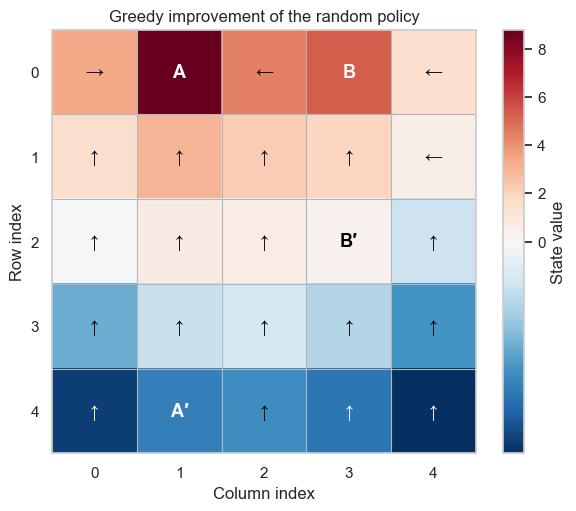

In [5]:
def improve_policy_greedily(values: FloatArray) -> FloatArray:
    """Build a greedy policy from state values, splitting ties equally.

    Args:
        values: State values indexed by row and column.

    Returns:
        Action probabilities indexed by row, column, and action.
    """
    policy = np.zeros((GRID_SIZE, GRID_SIZE, N_ACTIONS))
    for state in states():
        row, column = state
        q_values = action_values(values, state)
        best_actions = np.flatnonzero(np.isclose(q_values, q_values.max()))
        policy[row, column, best_actions] = 1.0 / len(best_actions)
    return policy


first_improved_policy = improve_policy_greedily(random_values)
plot_policy(
    first_improved_policy,
    "Greedy improvement of the random policy",
    random_values,
)

## 4. Policy iteration

**Policy iteration** alternates two complete operations:

1. **Policy evaluation:** calculate $v_\pi$ for the current policy.
2. **Policy improvement:** replace that policy with $\mathrm{greedy}(v_\pi)$.

When the greedy step leaves the policy unchanged, the policy is optimal. This works here because we know the transition and reward model exactly.

All optimal state values here are positive, so the heatmaps use the observed range: blue means a lower value in the grid, not a negative return.

 policy update  evaluation sweeps  policy stable
             0                 47          False
             1                111          False
             2                111          False
             3                111          False
             4                111           True


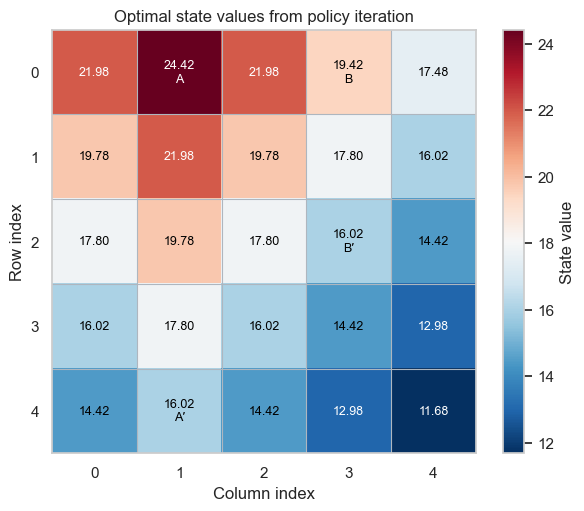

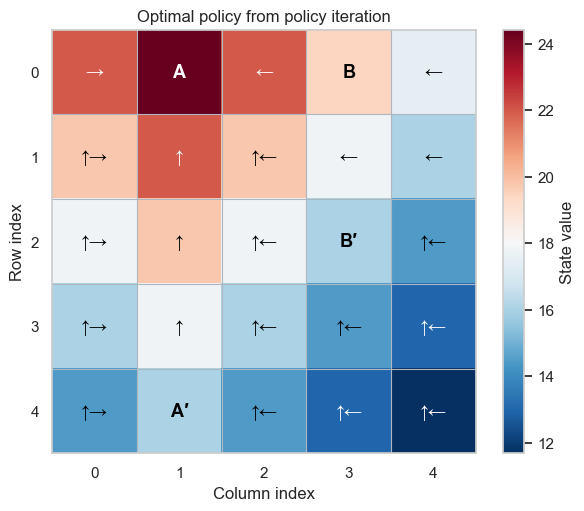

In [6]:
def policy_iteration(
    tolerance: float = 1e-4, max_policy_updates: int = 50
) -> tuple[FloatArray, FloatArray, pd.DataFrame]:
    """Alternate complete policy evaluation and greedy improvement.

    Args:
        tolerance: Convergence threshold within each policy evaluation.
        max_policy_updates: Maximum number of evaluate-and-improve rounds.

    Returns:
        The final values, the stable policy, and a table of the rounds.

    Raises:
        RuntimeError: If evaluation fails to converge or the policy is unstable
            after max_policy_updates rounds.
    """
    policy = uniform_random_policy()
    history = []

    for update_idx in range(max_policy_updates):
        values, evaluation_changes = evaluate_policy(
            policy, tolerance=tolerance
        )
        improved_policy = improve_policy_greedily(values)
        stable = np.allclose(improved_policy, policy)
        history.append({
            "policy update": update_idx,
            "evaluation sweeps": len(evaluation_changes),
            "policy stable": stable,
        })
        if stable:
            return values, policy, pd.DataFrame(history)
        policy = improved_policy

    raise RuntimeError("Policy iteration did not stabilize.")


values_from_policy_iteration, policy_from_policy_iteration, policy_history = (
    policy_iteration()
)
print(policy_history.to_string(index=False))
plot_values(
    values_from_policy_iteration, "Optimal state values from policy iteration"
)
plot_policy(
    policy_from_policy_iteration,
    "Optimal policy from policy iteration",
    values_from_policy_iteration,
)

## 5. Value iteration

Policy iteration evaluates one policy fully before improving it. **Value iteration** applies the Bellman optimality update directly. Let $q_k(s,a)$ be the one-step score for action $a$ computed from the current value estimate $v_k$, rather than from the value function of a fixed policy:

$$
\begin{aligned}
v_{k+1}(s) &= \max_a q_k(s,a) \\
&= \max_a \left[r(s,a,s') + \gamma v_k(s')\right].
\end{aligned}
$$

There is no explicit policy during the updates. After the values converge, we extract the policy by taking the greedy action at each state.

Value iteration converged in 111 sweeps.
Maximum difference from policy iteration: 0.00e+00


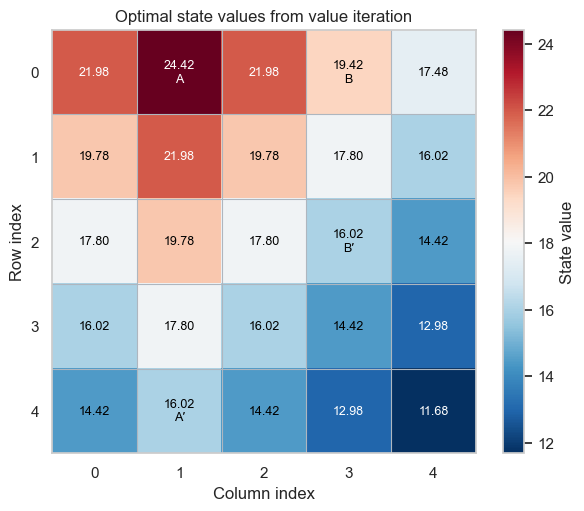

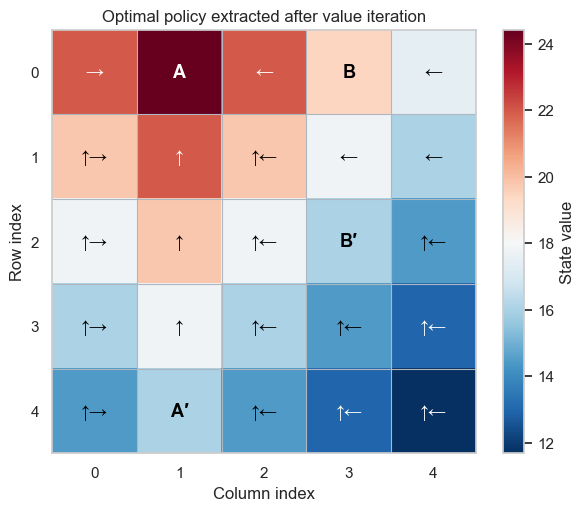

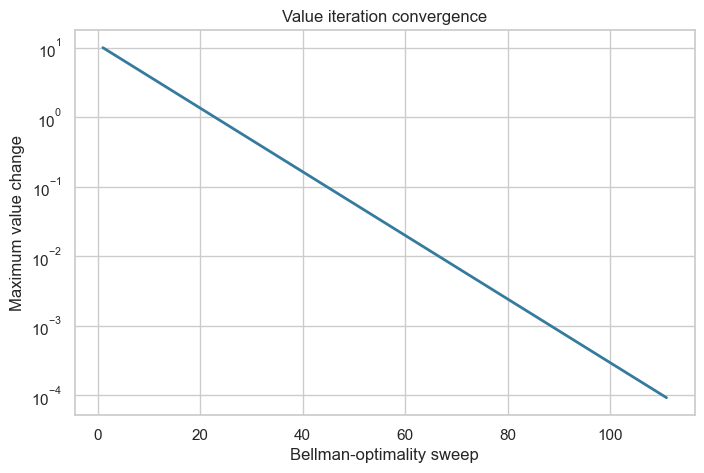

In [7]:
def value_iteration(
    tolerance: float = 1e-4, max_sweeps: int = 10_000
) -> tuple[FloatArray, FloatArray, FloatArray]:
    """Apply synchronous Bellman optimality backups until convergence.

    Args:
        tolerance: Stop when the maximum value change falls below this.
        max_sweeps: Maximum number of Bellman sweeps.

    Returns:
        The final values, the policy greedy with respect to those values,
        and the maximum value change from each sweep.

    Raises:
        RuntimeError: If the values do not converge within max_sweeps.
    """
    values = np.zeros((GRID_SIZE, GRID_SIZE))
    changes = []

    for _ in range(max_sweeps):
        next_values = np.zeros_like(values)
        for state in states():
            next_values[state] = action_values(values, state).max()

        max_change = np.max(np.abs(next_values - values))
        changes.append(max_change)
        values = next_values
        if max_change < tolerance:
            break
    else:
        raise RuntimeError("Value iteration did not converge.")

    policy = improve_policy_greedily(values)
    return values, policy, np.asarray(changes)


values_from_value_iteration, policy_from_value_iteration, value_changes = (
    value_iteration()
)
max_difference = np.max(
    np.abs(values_from_policy_iteration - values_from_value_iteration)
)
print(f"Value iteration converged in {len(value_changes)} sweeps.")
print(f"Maximum difference from policy iteration: {max_difference:.2e}")

plot_values(
    values_from_value_iteration, "Optimal state values from value iteration"
)
plot_policy(
    policy_from_value_iteration,
    "Optimal policy extracted after value iteration",
    values_from_value_iteration,
)

fig, ax = plt.subplots()
ax.semilogy(
    np.arange(1, len(value_changes) + 1),
    value_changes,
    color="#347b9e",
    linewidth=2,
)
ax.set(
    xlabel="Bellman-optimality sweep",
    ylabel="Maximum value change",
    title="Value iteration convergence",
)
plt.show()

## Takeaways

- A state value averages action values under a specified policy.
- Policy iteration alternates full evaluation with greedy improvement.
- Value iteration uses a maximum in every backup, then extracts a greedy policy after convergence.
- Both methods rely on the known Gridworld transition and reward model. Later, model-free methods must learn from sampled experience instead.

[← Return to Reinforcement learning](index.qmd)